# 第三次个人作业（内容包括机器学习与社会网络分析部分已经讲过的内容，满分15分；最后折合成总成绩中的10分）
### 请将作业按照“学号-姓名-第三次作业”的格式命名
### 注意：①使用markdown完成说明 ②使用相对路径 ③对于指标的选择理由以及可视化的内容需要适当的说明

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, 
                             roc_curve, auc, RocCurveDisplay)
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt 
import seaborn as sns
plt.rcParams['font.sans-serif']=['SimHei']  #解决中文字体显示乱码问题
plt.rcParams['axes.unicode_minus']=False
sns.set(font='SimHei')


### 第三次作业（1）：机器学习与社会网络分析（满分15分）

## 第三次作业（1）：机器学习与社会网络分析

### 作业要求：

1. 完成第三次作业（1）：机器学习与社会网络分析（满分15分）；

### 第一部分：机器学习（本部分满分10分）

1.1（共7分）请针对Cylinder Bands数据集（bands.data文件）以最后一个字段（band type）为标签，利用第5个至第39个字段为特征建立分类模型。  
数据集介绍请参考[链接](https://archive.ics.uci.edu/ml/datasets/Cylinder+Bands)。注意，模型准确率不影响本作业的得分。

作业具体要求如下：

1.1.1 数据预处理（2分）  
(1) 选择合适的预处理处理方式对标称变量编码（1分）；   
(2) 检视缺失值情况，并选择合适方式对缺失值填充（1分）。  


In [4]:
# 加载数据，处理缺失值
df= pd.read_csv('bands.data', header=None, na_values='?')
df.head()


,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,19910108,X126,TVGUIDE,25503.0,YES,KEY,YES,BENTON,GALLATIN,UNCOATED,...,36.4,0.0,0.0,2.5,1.0,34.0,40.0,105.00,100.0,band
1,19910109,X266,TVGUIDE,25503.0,YES,KEY,YES,BENTON,GALLATIN,UNCOATED,...,38.5,0.0,0.0,2.5,0.7,34.0,40.0,105.00,100.0,noband
2,19910104,B7,MODMAT,47201.0,YES,KEY,YES,BENTON,GALLATIN,UNCOATED,...,39.8,0.0,0.0,2.8,0.9,40.0,40.0,103.87,100.0,noband
3,19910104,T133,MASSEY,39039.0,YES,KEY,YES,BENTON,GALLATIN,UNCOATED,...,38.8,0.0,0.0,2.5,1.3,40.0,40.0,108.06,100.0,noband
4,19910111,J34,KMART,37351.0,NO,KEY,YES,BENTON,GALLATIN,UNCOATED,...,42.5,5.0,0.0,2.3,0.6,35.0,40.0,106.67,100.0,noband


In [5]:
# 分割特征与标签
X = df.iloc[:, 4:39]  # 第5至第39字段为特征
y = df.iloc[:, -1]    # 最后一列为标签

In [6]:

# 分离标称变量和数值变量
nominal_cols = X.select_dtypes(include=['object']).columns
numeric_cols = X.select_dtypes(include=['number']).columns

# 填充缺失值
for col in nominal_cols:
    mode_val = X[col].mode()[0]
    X[col].fillna(mode_val, inplace=True)
for col in numeric_cols:
    mean_val = X[col].mean()
    X[col].fillna(mean_val, inplace=True)

X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 35 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   4       541 non-null    object 
 1   5       541 non-null    object 
 2   6       541 non-null    object 
 3   7       541 non-null    object 
 4   8       541 non-null    object 
 5   9       541 non-null    object 
 6   10      541 non-null    object 
 7   11      541 non-null    object 
 8   12      541 non-null    object 
 9   13      541 non-null    object 
 10  14      541 non-null    object 
 11  15      541 non-null    float64
 12  16      541 non-null    float64
 13  17      541 non-null    object 
 14  18      541 non-null    object 
 15  19      541 non-null    float64
 16  20      541 non-null    float64
 17  21      541 non-null    float64
 18  22      541 non-null    object 
 19  23      541 non-null    float64
 20  24      541 non-null    float64
 21  25      541 non-null    float64
 22  26

C:\Users\19268\AppData\Local\Temp\ipykernel_16976\1918722548.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X[col].fillna(mode_val, inplace=True)
C:\Users\19268\AppData\Local\Temp\ipykernel_16976\1918722548.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when

In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X[nominal_cols] =X[nominal_cols].apply(le.fit_transform)
y = le.fit_transform(y)
X.head()

,4,5,6,7,8,9,10,11,12,13,...,29,30,31,32,33,34,35,36,37,38
0,2,1,2,1,1,2,2,1,0,1,...,50.5,36.4,0.0,0.0,2.5,1.0,34.0,40.0,105.00,100.0
1,2,1,2,1,1,2,2,1,0,1,...,54.9,38.5,0.0,0.0,2.5,0.7,34.0,40.0,105.00,100.0
2,2,1,2,1,1,2,0,1,0,1,...,53.8,39.8,0.0,0.0,2.8,0.9,40.0,40.0,103.87,100.0
3,2,1,2,1,1,2,2,1,0,1,...,55.6,38.8,0.0,0.0,2.5,1.3,40.0,40.0,108.06,100.0
4,1,1,2,1,1,2,0,1,0,1,...,57.5,42.5,5.0,0.0,2.3,0.6,35.0,40.0,106.67,100.0


缺失值比较多，若完全删除将会损失大量数据。对数值型可选用求取均值的方式进行填充，对类别型变量可选用众数的方式进行填充。对类别型变量进行编码，可以使得模型更容易学习到特征之间的关系。

1.1.2 建立模型（2分）：选择2个不同的模型进行建模，基于特征（第5-39个字段）预测标签（最后一个字段）并统计训练准确率（Accuracy）。

In [8]:
from sklearn.model_selection import train_test_split
y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
# 切分数据集

In [9]:
#导入分类模型 
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score
import time
from sklearn.metrics import confusion_matrix as CM
from sklearn.metrics import roc_curve,auc,roc_auc_score

clf1 = GaussianNB()
clf2 = RandomForestClassifier()

In [10]:
for clf, label in zip([clf1, clf2], [
       'Bayes', '随机森林'
]):
    scores = cross_val_score(clf, X_train, y_train, scoring='accuracy', cv=2)
    print("Accuracy: %0.6f (+/- %0.2f)模型名称:[%s]" %
          (scores.mean(), scores.std(), label))

Accuracy: 0.636574 (+/- 0.01)模型名称:[Bayes]
Accuracy: 0.743056 (+/- 0.02)模型名称:[随机森林]


1.1.3 模型比较（3分）  
(1) 比较不同模型的混淆矩阵（1分）；  
(2) 比较不同模型的ROC曲线（1分） ；   
(3) 比较不同模型的AUC值（1分） 。

[[11 30]
 [ 3 65]]


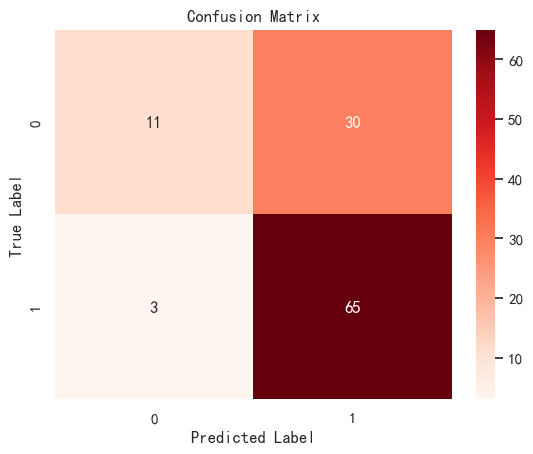

In [11]:
#混淆矩阵
clf1.fit(X_train,y_train)
y_test_preds = clf1.predict(X_test)
cm = CM(y_test, y_test_preds)
print(cm)
labels=[0,1]
sns.heatmap(cm,annot=True,fmt="d",xticklabels=labels,yticklabels=labels,cmap=plt.get_cmap('Reds'))
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

In [12]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
# 计算准确率
accuracy = accuracy_score(y_test, y_test_preds)
print(f"准确率: {accuracy:.6f}")

# 计算精准率
precision = precision_score(y_test, y_test_preds, average='binary')
print(f"精准率: {precision:.6f}")

# 计算召回率
recall = recall_score(y_test, y_test_preds, average='binary')
print(f"召回率: {recall:.6f}")

# 计算F1分数
f1 = 2 * (precision * recall) / (precision + recall)
print(f"F1 分数: {f1:.6f}")

准确率: 0.697248
精准率: 0.684211
召回率: 0.955882
F1 分数: 0.797546


[[33  8]
 [ 4 64]]


Text(49.25, 0.5, 'True Label')

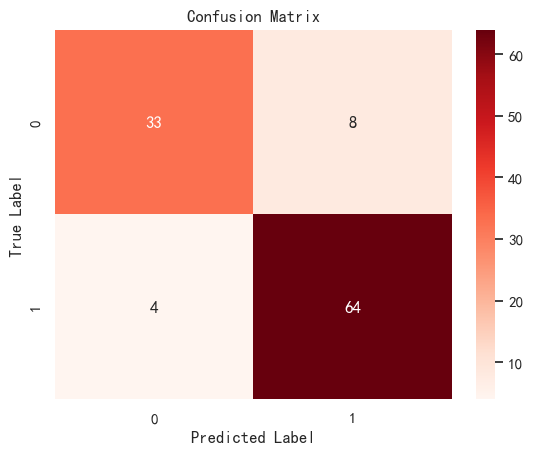

In [13]:
clf2.fit(X_train,y_train)
y_test_preds = clf2.predict(X_test)
cm = CM(y_test, y_test_preds)
print(cm)
labels=[0,1]
sns.heatmap(cm,annot=True,fmt="d",xticklabels=labels,yticklabels=labels,cmap=plt.get_cmap('Reds'))
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')


In [14]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
# 计算准确率
accuracy = accuracy_score(y_test, y_test_preds)
print(f"准确率: {accuracy:.6f}")

# 计算精准率
precision = precision_score(y_test, y_test_preds, average='binary')
print(f"精准率: {precision:.6f}")

# 计算召回率
recall = recall_score(y_test, y_test_preds, average='binary')
print(f"召回率: {recall:.6f}")

# 计算F1分数
f1 = 2 * (precision * recall) / (precision + recall)
print(f"F1 分数: {f1:.6f}")

准确率: 0.889908
精准率: 0.888889
召回率: 0.941176
F1 分数: 0.914286


如图可知\
朴素贝叶斯的*准确率: 0.697248
精准率: 0.684211
召回率: 0.955882
F1 分数: 0.797546*
\
随机森林的*准确率: 0.889908
精准率: 0.888889
召回率: 0.941176
F1 分数: 0.914286*\

可知，随机森林的准确率、精准率，F1分数都更高，二者的召回率相差不多，说明随机森林更优越


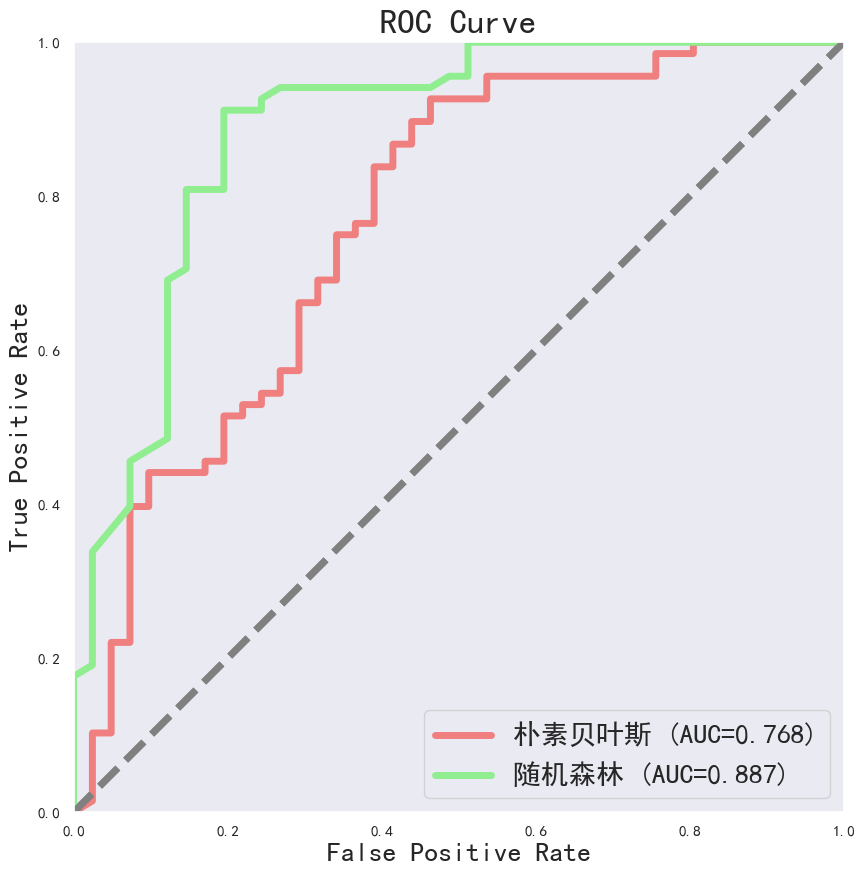

In [15]:
#ROC曲线
names = ['朴素贝叶斯','随机森林']
clfs = [clf1,clf2]
colors = ['lightcoral', 'lightgreen']
plt.figure(figsize=(10, 10))
for (name, clf, colorname) in zip (names, clfs, colors):
    clf.fit(X_train,y_train)
    y_test_preds = clf.predict(X_test)
    y_test_predprob = clf.predict_proba(X_test)[:,1]
    fpr, tpr, thresholds = roc_curve(y_test, y_test_predprob, pos_label=1)
    
    plt.plot(fpr, tpr, lw=5, label='{} (AUC={:.3f})'.format(name, auc(fpr, tpr)),color = colorname)
    plt.plot([0, 1], [0, 1], '--', lw=5, color = 'grey')
    plt.axis('square')
    plt.xlim([0, 1])
    plt.ylim([0, 1])
    plt.xlabel('False Positive Rate',fontsize=20)
    plt.ylabel('True Positive Rate',fontsize=20)
    plt.title('ROC Curve',fontsize=25)
    plt.grid(False)
    plt.legend(loc='lower right',fontsize=20)

plt.show()

如图可见，随机森林的ROV曲线完全包住了朴素贝叶斯的曲线，说明随机森林的预测能力更强

In [16]:
#AUC值
clf1.fit(X_train,y_train)
y_test_predprob = clf1.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_test_predprob, pos_label=1)
print('AUC:', auc(fpr, tpr))    

AUC: 0.7681133428981348


In [17]:
clf2.fit(X_train,y_train)
y_test_predprob = clf2.predict_proba(X_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_test_predprob, pos_label=1)
print('AUC:', auc(fpr, tpr))    

AUC: 0.8970588235294118


从AUC值来看，随机森林的AUC值更高，说明随机森林的预测能力更强

1.2.请利用"BASKETS.txt"数据集进行关联规则挖掘。（共3分）  
作业具体要求如下：

In [18]:
url='BASKETS.txt'
df = pd.read_csv(url,sep=',')
df.head()

,cardid,value,pmethod,sex,homeown,income,age,fruitveg,freshmeat,dairy,cannedveg,cannedmeat,frozenmeal,beer,wine,softdrink,fish,confectionery
0,39808,42.7123,CHEQUE,M,NO,27000,46,F,T,T,F,F,F,F,F,F,F,T
1,67362,25.3567,CASH,F,NO,30000,28,F,T,F,F,F,F,F,F,F,F,T
2,10872,20.6176,CASH,M,NO,13200,36,F,F,F,T,F,T,T,F,F,T,F
3,26748,23.6883,CARD,F,NO,12200,26,F,F,T,F,F,F,F,T,F,F,F
4,91609,18.8133,CARD,M,YES,11000,24,F,F,F,F,F,F,F,F,F,F,F


1.2.1 探索性数据分析（1分）  
(1) 分析数据集中fruitveg, freshmeat, dairy, cannedveg, cannedmeat, frozenmeal, beer, wine, softdrink, fish, confectionery各个字段分布情况，并绘图展示（1分）

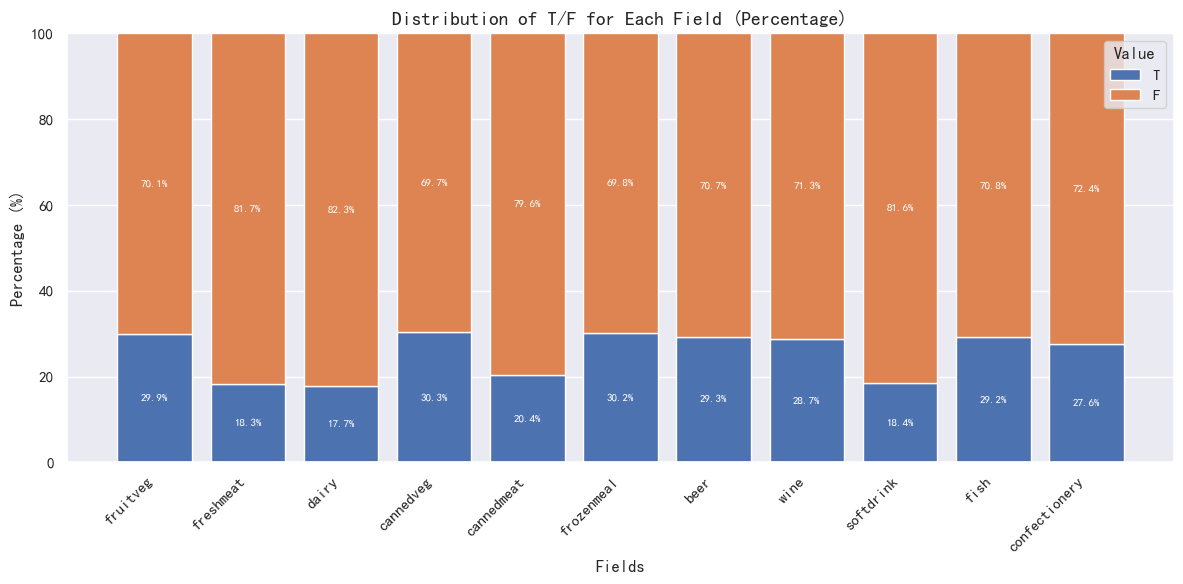

In [19]:
columns = ['fruitveg', 'freshmeat', 'dairy', 'cannedveg', 'cannedmeat', 'frozenmeal', 'beer', 'wine','softdrink', 'fish', 'confectionery']
counts = pd.DataFrame({
    "T": df[columns].apply(lambda x: (x == "T").sum()),
    "F": df[columns].apply(lambda x: (x == "F").sum())
})

# 计算百分比
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

plt.figure(figsize=(12, 6))

# 绘制堆叠条形图
bars = plt.bar(
    percentages.index,
    percentages["T"],
    label="T",
    color="#4C72B0"
)
plt.bar(
    percentages.index,
    percentages["F"],
    bottom=percentages["T"],
    label="F",
    color="#DD8452"
)

# 添加百分比标签（可选）
for bar, t_pct, f_pct in zip(bars, percentages["T"], percentages["F"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        t_pct / 2,  # 在T区域中间显示百分比
        f"{t_pct:.1f}%",
        ha="center", va="center", color="white", fontsize=8
    )
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        t_pct + f_pct / 2,  # 在F区域中间显示百分比
        f"{f_pct:.1f}%",
        ha="center", va="center", color="white", fontsize=8
    )

# 设置图表样式
plt.title("Distribution of T/F for Each Field (Percentage)", fontsize=14)
plt.xlabel("Fields", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Value", loc="upper right")
plt.ylim(0, 100)  # 确保y轴从0到100%
plt.tight_layout()
plt.show()

1.2.2 关联规则挖掘（2分）  
(1) 利用fruitveg, freshmeat, dairy, cannedveg, cannedmeat, frozenmeal, beer, wine, softdrink, fish, confectionery字段进行关联规则挖掘
，可自行指定最小支持度和最小置信度阈值，并给出理由（1分）；     
(2) 选出至少4条找到的关联规则进行比较和解释（1分）。

最小支持度（min_support）：选择 0.04（即项集在至少 4% 的交易中出现）。
\
理由：
过高的支持度（如>4%）可能遗漏低频但有价值的规则（如节日商品组合）。
过低的支持度（如<0.1%）会产生大量无意义的规则。
5%平衡了规则的代表性和可解释性。
\
最小置信度（min_confidence）：选择 0.6。
\
理由：
置信度<50%的规则随机性较强（如抛硬币概率）。
60%确保规则具备一定可信度，同时保留潜在业务价值（如促销组合）。

In [20]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
binary_matrix = df[columns].applymap(lambda x: 1 if x == "T" else 0)
# 生成频繁项集
frequent_itemsets = apriori(binary_matrix, min_support=0.04, use_colnames=True)

# 生成关联规则
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)

# 查看生成的关联规则
rules

C:\Users\19268\AppData\Local\Temp\ipykernel_16976\4229442920.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  binary_matrix = df[columns].applymap(lambda x: 1 if x == "T" else 0)
C:\Users\19268\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"(cannedveg, cannedmeat)",(frozenmeal),0.073,0.302,0.044,0.602740,1.995827,1.0,0.021954,1.757034,0.538247,0.132931,0.430859,0.374218
1,"(cannedmeat, beer)",(cannedveg),0.060,0.303,0.041,0.683333,2.255226,1.0,0.022820,2.201053,0.592112,0.127329,0.545672,0.409323
2,"(frozenmeal, cannedveg)",(beer),0.173,0.293,0.146,0.843931,2.880309,1.0,0.095311,4.530037,0.789377,0.456250,0.779251,0.671112
3,"(frozenmeal, beer)",(cannedveg),0.170,0.303,0.146,0.858824,2.834401,1.0,0.094490,4.937083,0.779749,0.446483,0.797451,0.670336
4,"(cannedveg, beer)",(frozenmeal),0.167,0.302,0.146,0.874251,2.894873,1.0,0.095566,5.550762,0.785788,0.452012,0.819845,0.678848
5,"(cannedmeat, beer)",(frozenmeal),0.060,0.302,0.040,0.666667,2.207506,1.0,0.021880,2.094000,0.581915,0.124224,0.522445,0.399558
6,"(frozenmeal, wine)",(beer),0.071,0.293,0.043,0.605634,2.067010,1.0,0.022197,1.792750,0.555661,0.133956,0.442198,0.376196
7,"(frozenmeal, cannedveg, fruitveg)",(beer),0.045,0.293,0.040,0.888889,3.033750,1.0,0.026815,6.363000,0.701963,0.134228,0.842841,0.512704
8,"(frozenmeal, beer, fruitveg)",(cannedveg),0.047,0.303,0.040,0.851064,2.808792,1.0,0.025759,4.679857,0.675735,0.129032,0.786318,0.491539
9,"(cannedveg, beer, fruitveg)",(frozenmeal),0.046,0.302,0.040,0.869565,2.879355,1.0,0.026108,5.351333,0.684172,0.129870,0.813131,0.501008


* "(cannedmeat, cannedveg)",(frozenmeal) :这三种产品都是耐储存的产品，可能是顾客需要长时间不出门储存物资，这种组合有利于营销
* "(frozenmeal, cannedveg)",(beer)：这三种产品的联系紧密，任意两个都和第三个之间有较高支持度，并且他们的提升度都很大，说明三者之间有相互促进的关系。冻肉、罐装蔬菜、啤酒三者搭配，荤素食物饮品搭配合理，说明这种组合适合营销。
* "(frozenmeal, fruitveg, cannedveg)",(beer) 这组的提升率很高，说明在买了肉、蔬菜、fruitveg之后，买啤酒的可能性很大。
* "(cannedveg, fish, beer)",(frozenmeal) 这组提升率也很高，同时置信度也很高，说明关联性强，但支持度不是很高，需要通过具体活动进行验证





### 第二部分：社会网络分析（本部分满分5分）

数据：来自微软学术图谱（MAG）中的引文数据集（见可视化部分的练习中的数据），author2paper表记录文献与作者的对应关系。

In [21]:
import networkx as nx

2.1 请构建作者和作者之间的合著网络（节点：作者；无向边：两个作者之间存在合著关系，即他们至少一次同时出现在一篇论文的作者列表中；边的权重：两个作者间的合著次数）。计算以下指标或回答以下问题（共2.5分）：

（1）网络中节点与边的数量（0.5分）；

（2）网络的密度和平均聚类系数（Average clustering coefficient）（0.5分）；

（3）对边权的分布做可视化，并对可视化结果做简要描述（0.5分）；

（4）对节点的度分布进行描述（0.5分）；

（5）选择网络中节点度数最高的5个节点，然后计算它们的degree centrality和closeness centrality（0.5分）

In [22]:
url='author2paper_table.txt'
author2paper = pd.read_csv(url,sep=';')
url='citation_table.txt'
citation= pd.read_csv(url,sep=';')
url='paper_table.txt'
paper_table = pd.read_csv(url,sep=';')

In [23]:
G=nx.Graph()
# 构建合著网络
for paper_id, group in author2paper.groupby('paper_id'):
    authors = group['author_id'].tolist()
    for i in range(len(authors)):
        for j in range(i + 1, len(authors)):
            if G.has_edge(authors[i], authors[j]):
                G[authors[i]][authors[j]]['weight'] += 1
            else:
                G.add_edge(authors[i], authors[j], weight=1)

# 计算网络指标
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()
density = nx.density(G)
avg_clustering = nx.average_clustering(G, weight='weight')

print(f"Number of nodes: {num_nodes}")
print(f"Number of edges: {num_edges}")
print(f"Density: {density}")
print(f"Average clustering coefficient: {avg_clustering}")

Number of nodes: 39906
Number of edges: 97760
Density: 0.00012277944762724668
Average clustering coefficient: 0.023767891525543705


In [24]:
edge_weights = [d['weight'] for (u, v, d) in G.edges(data=True)]


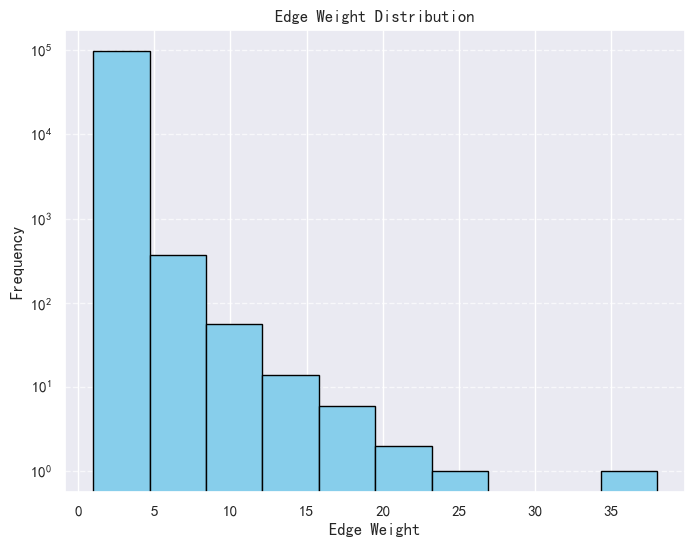

In [25]:
plt.figure(figsize=(8, 6))
plt.hist(edge_weights, color='skyblue', edgecolor='black')
plt.yscale('log')
plt.title('Edge Weight Distribution')
plt.xlabel('Edge Weight')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


如图可见，在对y轴取了对数之后，权重的频率随着权重的数量呈现下降趋势，且几乎是线性的，即说明权重分布随着权重的增长成指数下降。说明大多数作者之间的的关联都不深，只合作过少数文章，有很大关联即权重很大的很少。

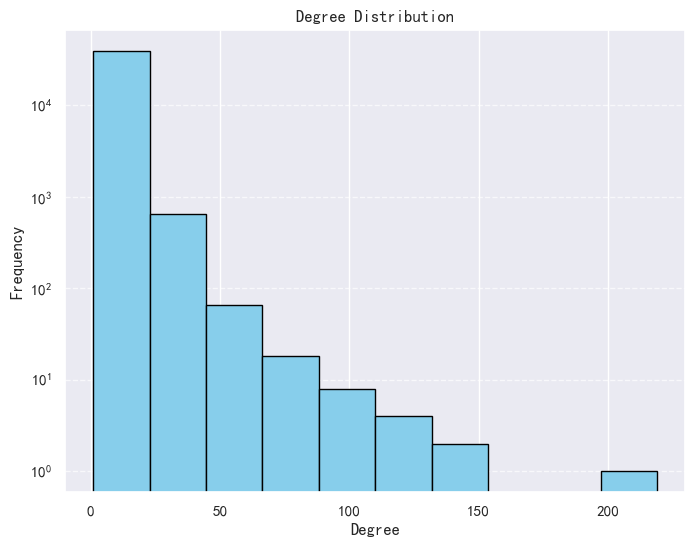

In [26]:
#对节点的度分布进行描述
degrees = [G.degree(n) for n in G.nodes()]

plt.figure(figsize=(8, 6))
plt.hist(degrees, color='skyblue', edgecolor='black')
plt.yscale('log')
plt.title('Degree Distribution')
plt.xlabel('Degree')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


    

如图可见，节点的度分布呈现长尾分布，即存在很多节点的度很少，只有很少的节点的度很大。

In [27]:
#选择网络中节点度数最高的5个节点，然后计算它们的degree centrality和closeness centrality（0.5分）
degree_dict = dict(G.degree())  # 格式：{节点: 度数}
sorted_degrees = sorted(degree_dict.items(), key=lambda x: x[1], reverse=True)
top5_nodes = [node for node, degree in sorted_degrees[:5]]  # 提取前5个节点
top5_nodes

[2122423217, 2150576810, 2147343253, 2122502592, 2083449707]

In [28]:
deg_centrality = nx.degree_centrality(G)
for node in top5_nodes:
    print(f"Node {node}:")
    print(f"Degree centrality: {deg_centrality[node]}")
    print()     

Node 2122423217:
Degree centrality: 0.005488034080942238

Node 2150576810:
Degree centrality: 0.0037088084199974943

Node 2147343253:
Degree centrality: 0.00345821325648415

Node 2122502592:
Degree centrality: 0.003182558576619471

Node 2083449707:
Degree centrality: 0.0031324395439168025



In [29]:
closeness_centrality = nx.closeness_centrality(G)
for node in top5_nodes  :
    print(f"Node {node}:")
    print(f"Closeness centrality: {closeness_centrality[node]}")
    print() 

Node 2122423217:
Closeness centrality: 0.058499750683553245

Node 2150576810:
Closeness centrality: 0.053578611662738584

Node 2147343253:
Closeness centrality: 0.05716571920681681

Node 2122502592:
Closeness centrality: 0.05449108221280845

Node 2083449707:
Closeness centrality: 0.051298338436456745



2.2 请构建论文和论文之间的引用网络（节点：论文，有向边：论文A引用了论文B，意即论文B出现在了A的参考文献列表中，边的权重：无）。计算以下指标或回答以下问题（共2.5分）：

（1）通过节点的中心性找出两个你认为比较“重要”的节点（结合各种中心性的特点和自己本地的计算速度选择一种指标即可），然后计算它们之间的最短路径（1分）；

（2）从现在的引用网络中构建一个子网络，这个子网络的所有节点在原引用网络都至少被引5次，这个子网络的边即上述筛选过的节点之间的引用关系。请使用边列表（edgelist）的形式将这个子网络写（write）入一个文件中。（1.5分）。


In [30]:
citation_graph = nx.DiGraph()
for _, row in citation.iterrows():
    citation_graph.add_edge(row['citing_id'], row['cited_id'])

# Task (1): Find two important nodes and calculate the shortest path
# Use in-degree centrality to find important nodes
degree_centrality = nx.in_degree_centrality(citation_graph)

important_nodes = sorted(degree_centrality, key=degree_centrality.get, reverse=True)[:2]
important_nodes

[2128495200, 1587026990]

In [31]:
shortest_path = nx.shortest_path(citation_graph, source=important_nodes[0], target=important_nodes[1])

NetworkXNoPath: No path between 2128495200 and 1587026990.

入度数最多的两个结点被定义为最重要的两个结点，他们之间没有通路，可能是由于他们是不同领域的文章，没有交叉。

In [32]:


# Task (2): Create a subnetwork with nodes having in-degree ≥ 5
subnetwork_nodes = [node for node, in_degree in citation_graph.in_degree() if in_degree >= 5]
subnetwork = citation_graph.subgraph(subnetwork_nodes)

# Save the subnetwork as an edge list
nx.write_edgelist(subnetwork, 'subnetwork_edgelist.txt', data=False)
print("Subnetwork edge list saved to 'subnetwork_edgelist.txt'")
url='subnetwork_edgelist.txt'
subnetwork_edgelist = pd.read_csv(url,header=None)
subnetwork_edgelist.head()


Subnetwork edge list saved to 'subnetwork_edgelist.txt'


,0
0,2292449291 2044102377
1,2062319644 2104451730
2,2062319644 2107260187
3,2062319644 2127534511
4,2062319644 2142365099
